# High-dimensional image embeddings: IMSTE and UMAP

Choose dataset, graph, optimizer, and rendering settings, then compare IMSTE with UMAP on the same standardized samples. Multilevel coarsening uses IMSTE graph ranks; by default, PCA of pooled coarse-group features initializes its smallest graph. Both embeddings are displayed with `render_datashader_embedding` to keep dense plots readable.

The full gallery, including class-mixture graph analysis, is archived at `notebooks/archive/00_high_dim_mst_gallery_full.ipynb`.

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "notebooks" / "src" / "high_dim_mst_gallery.py").is_file()),
    None,
)
if repo_root is not None:
    sys.path.insert(0, str(repo_root / "notebooks" / "src"))
    sys.path.insert(0, str(repo_root))

## 1. Select parameters and fit IMSTE

Set the number of samples and tune the distance metric, FAMST, IMSTE, multilevel, and optional gravity settings below. With `METRIC = "cosine"`, IMSTE uses exact Prim graph construction even when `MST_METHOD = "famst"`. With `PCA_INIT = True`, PCA of the pooled features represented by the coarsest groups starts the multilevel layout. Set it to `False` to use a seeded random start there.

The optional gravity phase builds density-weighted Leiden regions from the same standardized input, then applies density-core attraction and local Mexican-hat forces. Very close embedded neighbors repel; moderate-distance neighbors attract. It requires Euclidean features plus RINND, igraph, and leidenalg.

In [ ]:
from high_dim_mst_gallery import run_high_dim_mst_gallery
from IPython.display import display

# Dataset size
MAX_SAMPLES = 60_000
RANDOM_STATE = 42

# IMSTE graph and optimizer
MST_METHOD = "famst"  # or "prim" for exact graph construction
METRIC = "euclidean"  # or "cosine"; cosine uses exact Prim for IMSTE
DEVICE = "mps"  # IMSTE graph construction and optimization device
N_COMPONENTS = 2  # The comparison renderer uses the first two coordinates.
N_MSTS = 4
N_EPOCHS = 500
BATCH_SIZE = 32768
LEARNING_RATE = 0.05
NEGATIVE_RATIO = 1
LAMBDA_REP = 0.5
EPSILON = 1e-4
LOGISTIC_MARGIN = 1.0
LOGISTIC_TEMPERATURE = 0.5

# FAMST candidate graph (ignored by exact Prim construction)
MST_NEIGHBOR_BACKEND = "auto"  # "auto", "rinnd", "pynndescent", or "mps_exact"
MST_NEIGHBORS = 15
MST_INTER_COMPONENT_EDGES = 5
FAMST_MAX_NEIGHBORS = 15
MST_REPRESENTATIVES_PER_COMPONENT = 10

# Initialization
PCA_INIT = True  # Use PCA on the coarsest graph in the multilevel initializer.
PCA_INIT_SCALING = "global"  # "global" or "none"

# Multilevel initializer (enabled by default in this notebook)
MULTILEVEL_INIT = True
MULTILEVEL_REDUCTION_RATIO = 4
MULTILEVEL_BASE_SIZE = 1024
MULTILEVEL_EPOCHS = 10

# Optional density-gravity second phase (requires Euclidean metric)
IMSTE_GRAVITY_ENABLED = True
IMSTE_GRAVITY_MODE = "mexican_hat"  # "mexican_hat" or "density_core"
IMSTE_GRAVITY_STRENGTH = 0.4  # density-core attraction strength
IMSTE_GRAVITY_RESOLUTION = 0.8
IMSTE_GRAVITY_CORE_QUANTILE = 0.95
IMSTE_GRAVITY_MASS_POWER = 1.0
IMSTE_GRAVITY_NEIGHBORS = 15  # RINND feature-space graph
IMSTE_GRAVITY_ATTRACTION_STRENGTH = 0.5
IMSTE_GRAVITY_NEAR_REPULSION_STRENGTH = 1.5
IMSTE_GRAVITY_FORCE_NEIGHBORS = 8  # local neighbors in the current 2D layout
IMSTE_GRAVITY_ATTRACTION_RANGE = 1.0  # × local 2D neighbor radius
IMSTE_GRAVITY_REPULSION_RANGE = 0.2  # very local; × local 2D neighbor radius
IMSTE_GRAVITY_STEP_SIZE = 0.05
IMSTE_GRAVITY_ITERATIONS = 3

# UMAP comparison
UMAP_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_EPOCHS = 200
REPULSION_STRENGTH = 1

# Datashader display
RENDER_WIDTH = 700
RENDER_HEIGHT = 700
RENDER_MIN_ALPHA = 40
RENDER_SPREAD_PX = 1
RENDER_BACKGROUND = "white"  # Change to "black" to compare contrast.

# Load the image datasets and fit IMSTE. Sample image grids and the helper's
# scatter plots are disabled; the comparison below uses Datashader instead.
gallery = run_high_dim_mst_gallery(
    max_samples=MAX_SAMPLES,
    n_components=N_COMPONENTS,
    n_msts=N_MSTS,
    n_epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    pca_init=PCA_INIT,
    pca_init_scaling=PCA_INIT_SCALING,
    mst_method=MST_METHOD,
    mst_neighbor_backend=MST_NEIGHBOR_BACKEND,
    mst_neighbors=MST_NEIGHBORS,
    mst_inter_component_edges=MST_INTER_COMPONENT_EDGES,
    mst_representatives_per_component=MST_REPRESENTATIVES_PER_COMPONENT,
    metric=METRIC,
    device=DEVICE,
    negative_ratio=NEGATIVE_RATIO,
    lambda_rep=LAMBDA_REP,
    epsilon=EPSILON,
    logistic_margin=LOGISTIC_MARGIN,
    logistic_temperature=LOGISTIC_TEMPERATURE,
    mst_max_neighbors=FAMST_MAX_NEIGHBORS,
    random_state=RANDOM_STATE,
    plot_sample_images=False,
    plot_embeddings=False,
    multilevel_init=MULTILEVEL_INIT,
    multilevel_reduction_ratio=MULTILEVEL_REDUCTION_RATIO,
    multilevel_base_size=MULTILEVEL_BASE_SIZE,
    multilevel_epochs=MULTILEVEL_EPOCHS,
)
display(gallery["summary"])
if gallery["load_errors"]:
    display(gallery["load_errors"])


Loading MNIST (28×28) ...
  60,000 samples × 784 features; 10 classes
Loading Fashion-MNIST (28×28) ...
  60,000 samples × 784 features; 10 classes
Loading Kuzushiji-MNIST (28×28) ...
  60,000 samples × 784 features; 10 classes
Fitting MNIST (28×28) with FAMST (euclidean) on mps ...
  pipeline completed in 16.78 seconds
  standardized IMSTE input: 60,000 samples × 784 features
Fitting Fashion-MNIST (28×28) with FAMST (euclidean) on mps ...
  pipeline completed in 12.97 seconds
  standardized IMSTE input: 60,000 samples × 784 features
Fitting Kuzushiji-MNIST (28×28) with FAMST (euclidean) on mps ...
  pipeline completed in 13.09 seconds
  standardized IMSTE input: 60,000 samples × 784 features


,dataset,samples,input_features,features,classes,n_msts,mst_method,metric,mst_max_neighbors,n_epochs,negative_ratio,lambda_rep,pca_init,multilevel_init,multilevel_reduction_ratio,multilevel_base_size,multilevel_epochs,unique_graph_edges,seconds,device
0,MNIST (28×28),60000,784,784,10,4,famst,euclidean,15,500,1,0.5,True,True,4,1024,10,239996,16.779777,mps
1,Fashion-MNIST (28×28),60000,784,784,10,4,famst,euclidean,15,500,1,0.5,True,True,4,1024,10,239996,12.965398,mps
2,Kuzushiji-MNIST (28×28),60000,784,784,10,4,famst,euclidean,15,500,1,0.5,True,True,4,1024,10,239996,13.089691,mps


In [ ]:
import numpy as np
from arxiv_imste import fit_density_gravity_layout
from sklearn.preprocessing import StandardScaler
import hashlib
import json

IMSTE_GRAVITY_RESULTS = {}
IMSTE_GRAVITY_SECONDS = {}
if IMSTE_GRAVITY_ENABLED:
    if METRIC != "euclidean":
        raise ValueError("The gravity phase currently requires METRIC='euclidean'.")
    gravity_cache_dir = repo_root / "data" / "embeddings" / "gravity_cache"
    gravity_settings = {
        "enabled": True,
        "mode": IMSTE_GRAVITY_MODE,
        "strength": IMSTE_GRAVITY_STRENGTH,
        "resolution": IMSTE_GRAVITY_RESOLUTION,
        "core_quantile": IMSTE_GRAVITY_CORE_QUANTILE,
        "mass_power": IMSTE_GRAVITY_MASS_POWER,
        "neighbors": IMSTE_GRAVITY_NEIGHBORS,
        "attraction_strength": IMSTE_GRAVITY_ATTRACTION_STRENGTH,
        "near_repulsion_strength": IMSTE_GRAVITY_NEAR_REPULSION_STRENGTH,
        "force_neighbors": IMSTE_GRAVITY_FORCE_NEIGHBORS,
        "attraction_range": IMSTE_GRAVITY_ATTRACTION_RANGE,
        "repulsion_range": IMSTE_GRAVITY_REPULSION_RANGE,
        "step_size": IMSTE_GRAVITY_STEP_SIZE,
        "iterations": IMSTE_GRAVITY_ITERATIONS,
        "random_state": RANDOM_STATE,
        "metric": METRIC,
    }
    for dataset_name, (raw_X, labels) in gallery["datasets"].items():
        X_standardized = StandardScaler().fit_transform(raw_X)
        imste_coordinates = np.asarray(gallery["embeddings"][dataset_name], dtype=np.float32)
        layout_hash = hashlib.sha256(np.ascontiguousarray(imste_coordinates).view(np.uint8)).hexdigest()[:16]
        gravity_result = fit_density_gravity_layout(
            X_standardized, labels, imste_coordinates,
            cache_dir=gravity_cache_dir,
            projection_id=f"{dataset_name}-{layout_hash}",
            dataset_id=f"gallery-{dataset_name}-{len(labels)}-seed{RANDOM_STATE}",
            settings=gravity_settings,
            verbose=False,
        )
        if gravity_result["embedding"] is not None:
            IMSTE_GRAVITY_RESULTS[dataset_name] = gravity_result["embedding"]
            IMSTE_GRAVITY_SECONDS[dataset_name] = gravity_result["seconds"]
        print(
            f"{dataset_name}: gravity {'loaded from cache' if gravity_result['cache_hit'] else 'finished'} "
            f"in {gravity_result['seconds']:.1f}s; silhouette={gravity_result['silhouette']:.4f}"
        )


## 3. Fit UMAP to the same samples

The gallery helper standardizes features before IMSTE. This cell applies the same standardization to each raw dataset before fitting UMAP, so both methods receive matching input rows and feature scaling. Gravity uses the same standardized input and never uses UMAP coordinates.


In [3]:
from time import perf_counter

import umap
from IPython.display import display
from sklearn.preprocessing import StandardScaler

UMAP_RESULTS = {}
UMAP_SECONDS = {}
for dataset_name, (raw_X, labels) in gallery["datasets"].items():
    X_standardized = StandardScaler().fit_transform(raw_X)
    started = perf_counter()
    embedding = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        metric=METRIC,
        init="random",
        compatibility_layout=False,
        nearest_neighbor_backend="rinnd",
        random_state=RANDOM_STATE,
        n_epochs=UMAP_EPOCHS,
        repulsion_strength=REPULSION_STRENGTH,
        n_jobs=1,
    ).fit_transform(X_standardized)
    UMAP_RESULTS[dataset_name] = embedding
    UMAP_SECONDS[dataset_name] = perf_counter() - started
    print(f"{dataset_name}: UMAP fit in {UMAP_SECONDS[dataset_name] / 60:.1f} min")

comparison = gallery["summary"][["dataset", "samples", "input_features", "seconds"]].rename(
    columns={"seconds": "IMSTE seconds"}
)
comparison["UMAP seconds"] = comparison["dataset"].map(UMAP_SECONDS)
display(comparison)


MNIST (28×28): UMAP fit in 0.3 min
Fashion-MNIST (28×28): UMAP fit in 0.3 min
Kuzushiji-MNIST (28×28): UMAP fit in 0.4 min


,dataset,samples,input_features,IMSTE seconds,UMAP seconds
0,MNIST (28×28),60000,784,16.779777,19.715492
1,Fashion-MNIST (28×28),60000,784,12.965398,17.420821
2,Kuzushiji-MNIST (28×28),60000,784,13.089691,22.771373


## 4. Compare the embeddings with Datashader

Each panel rasterizes all points at the selected image size. Adjust the rendering settings above to change the mark spread, opacity, resolution, or background.


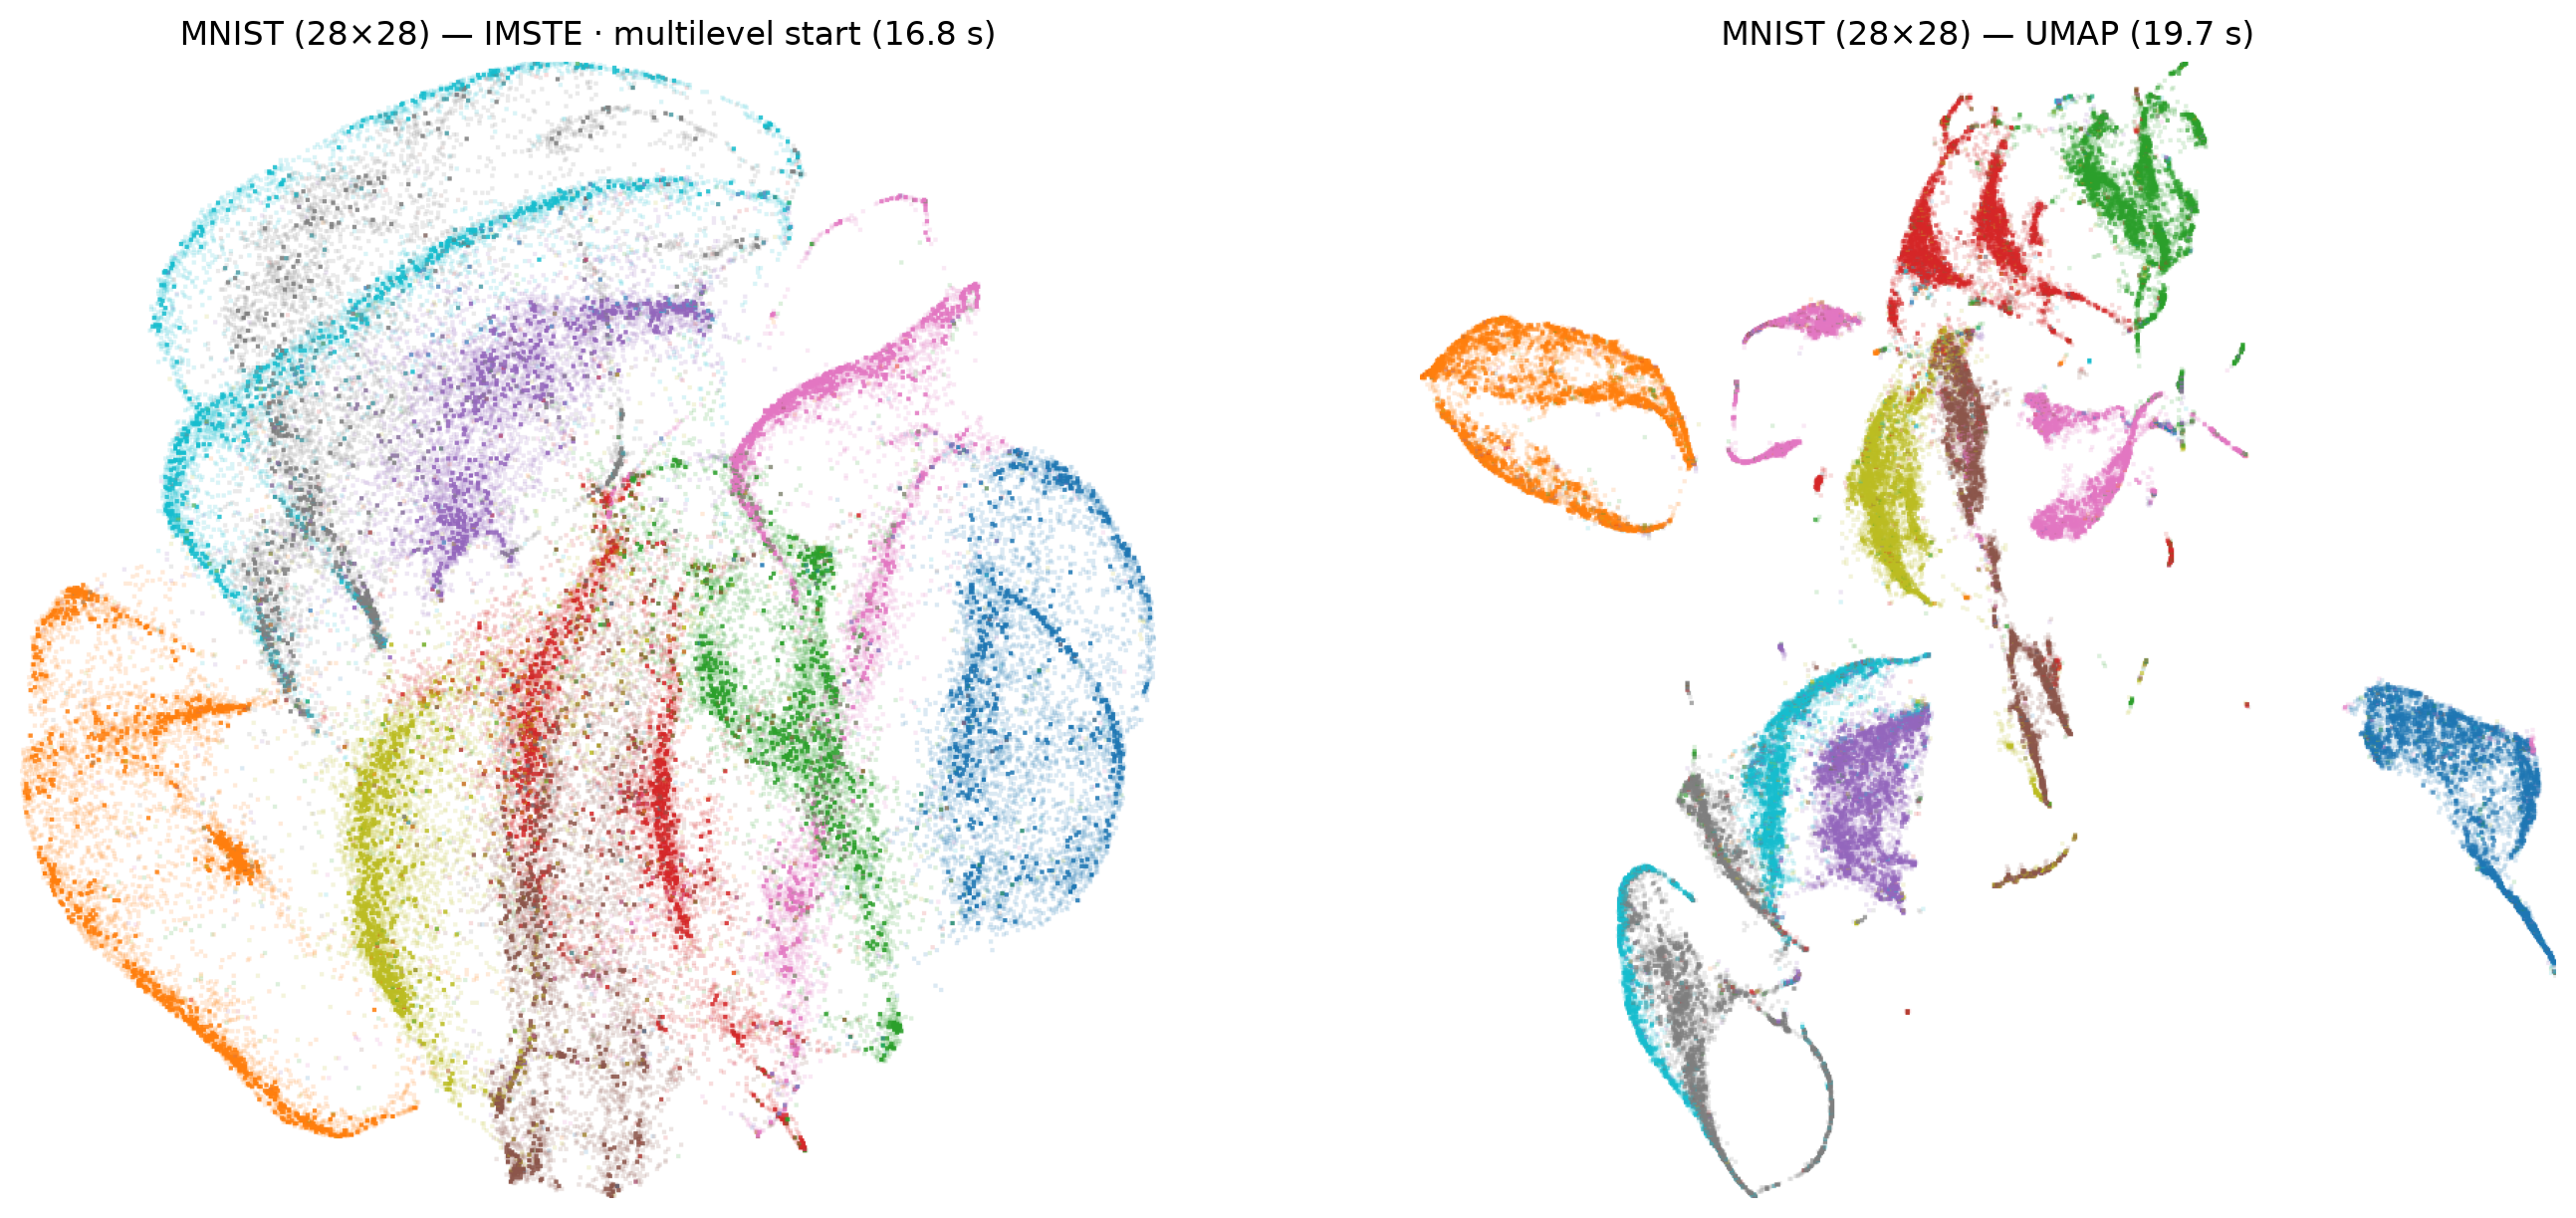

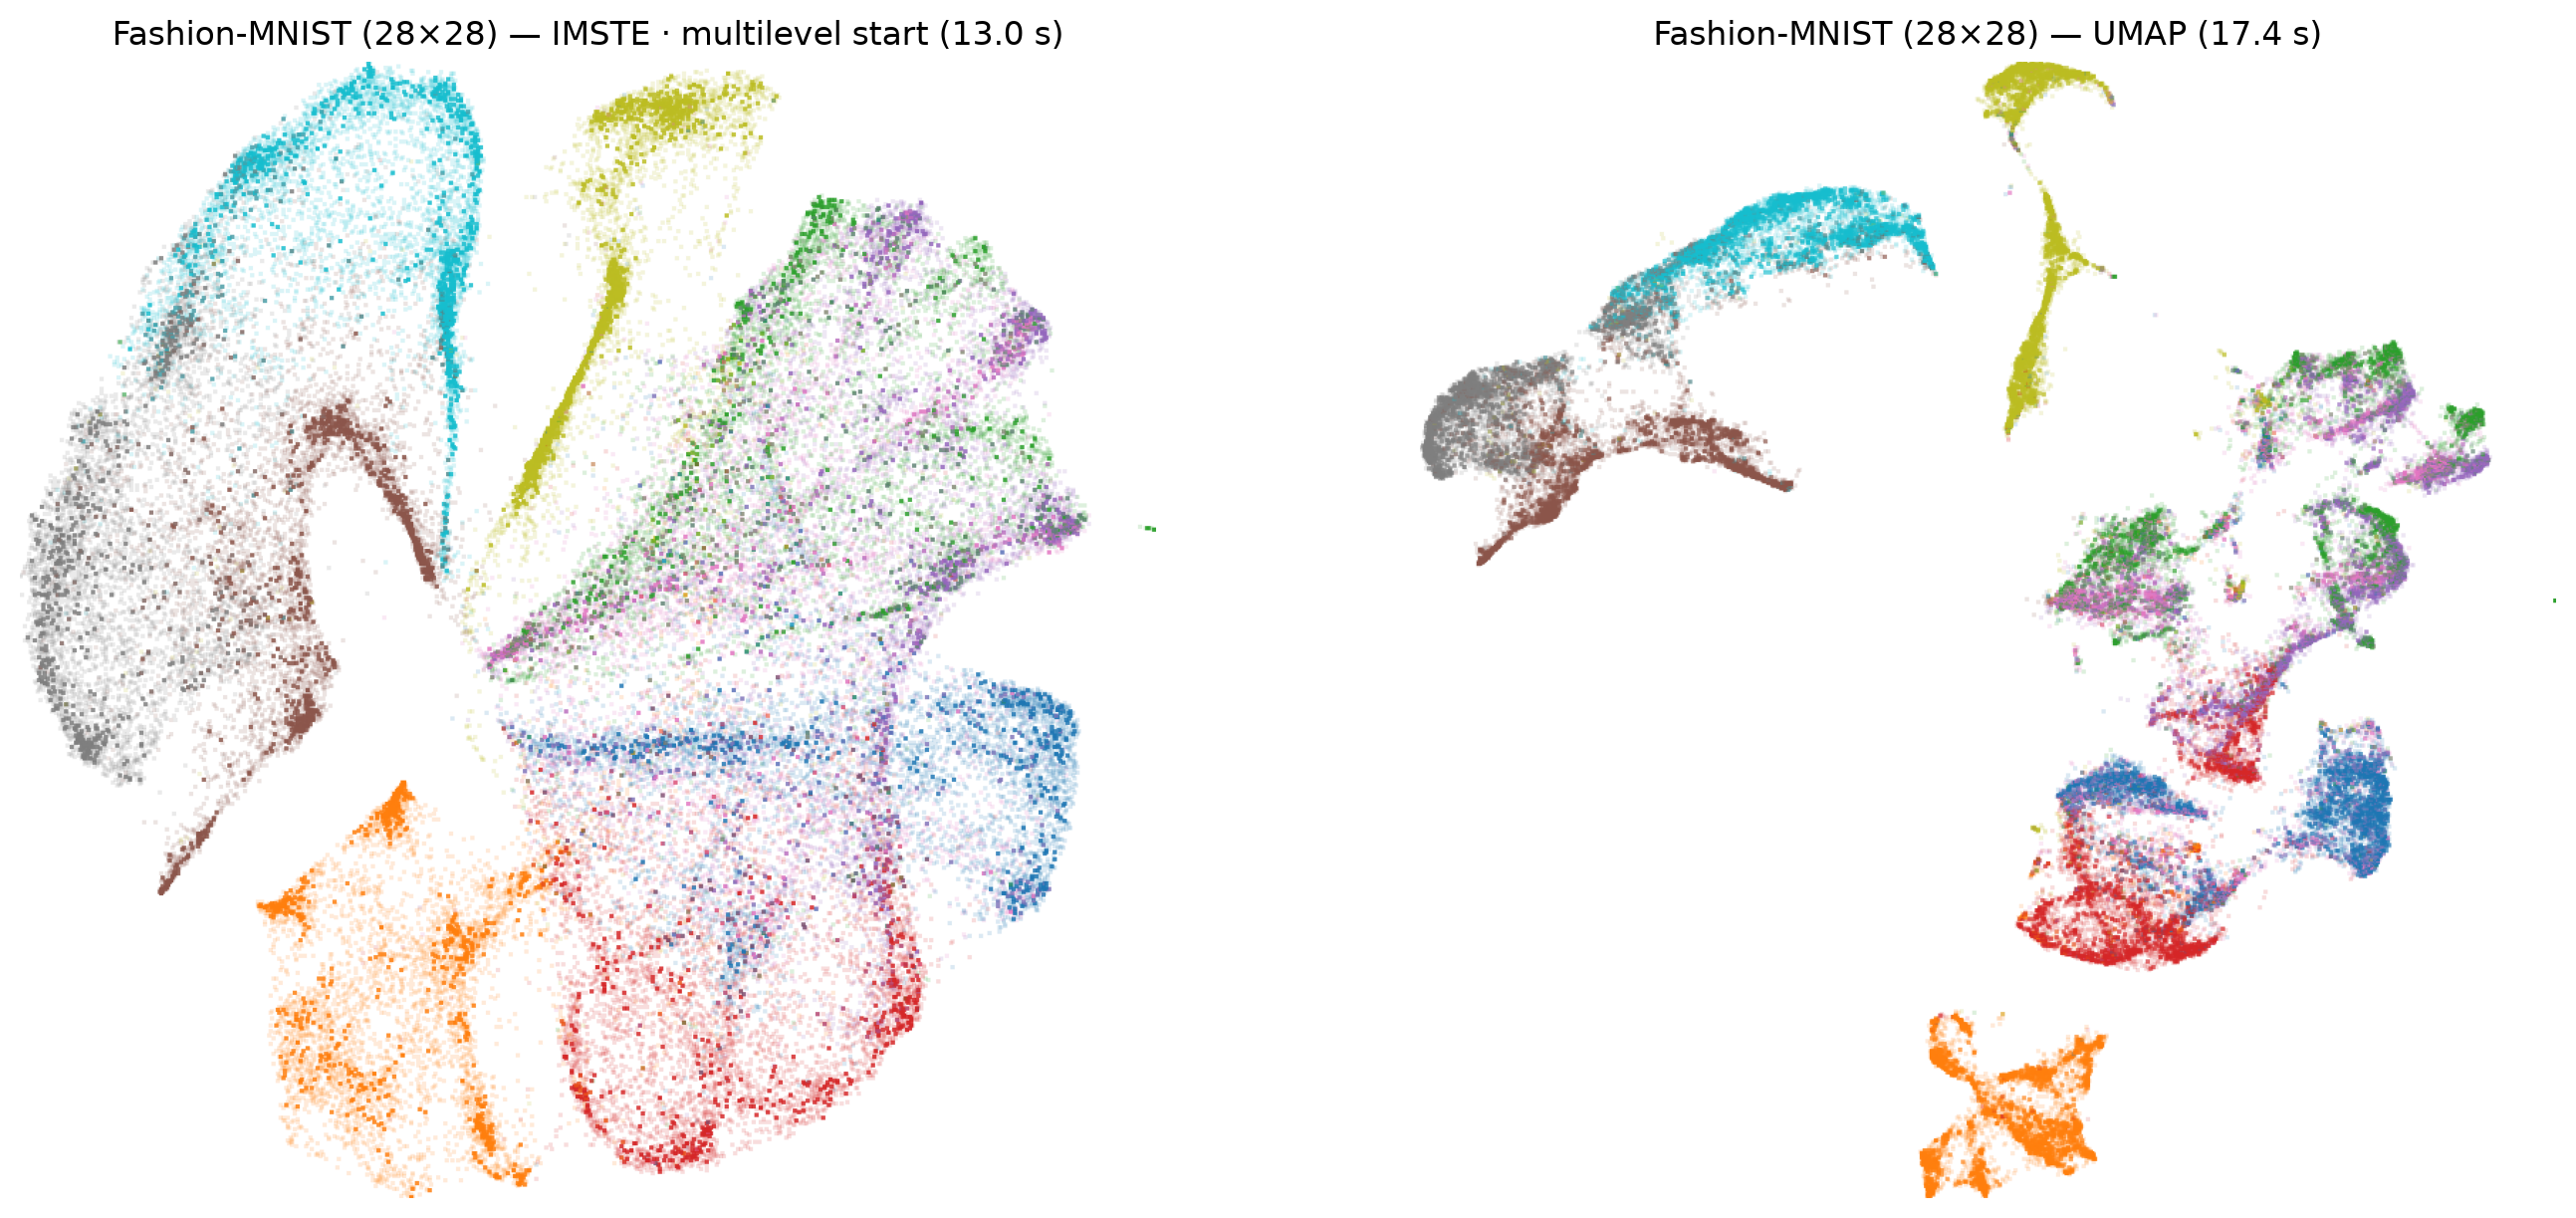

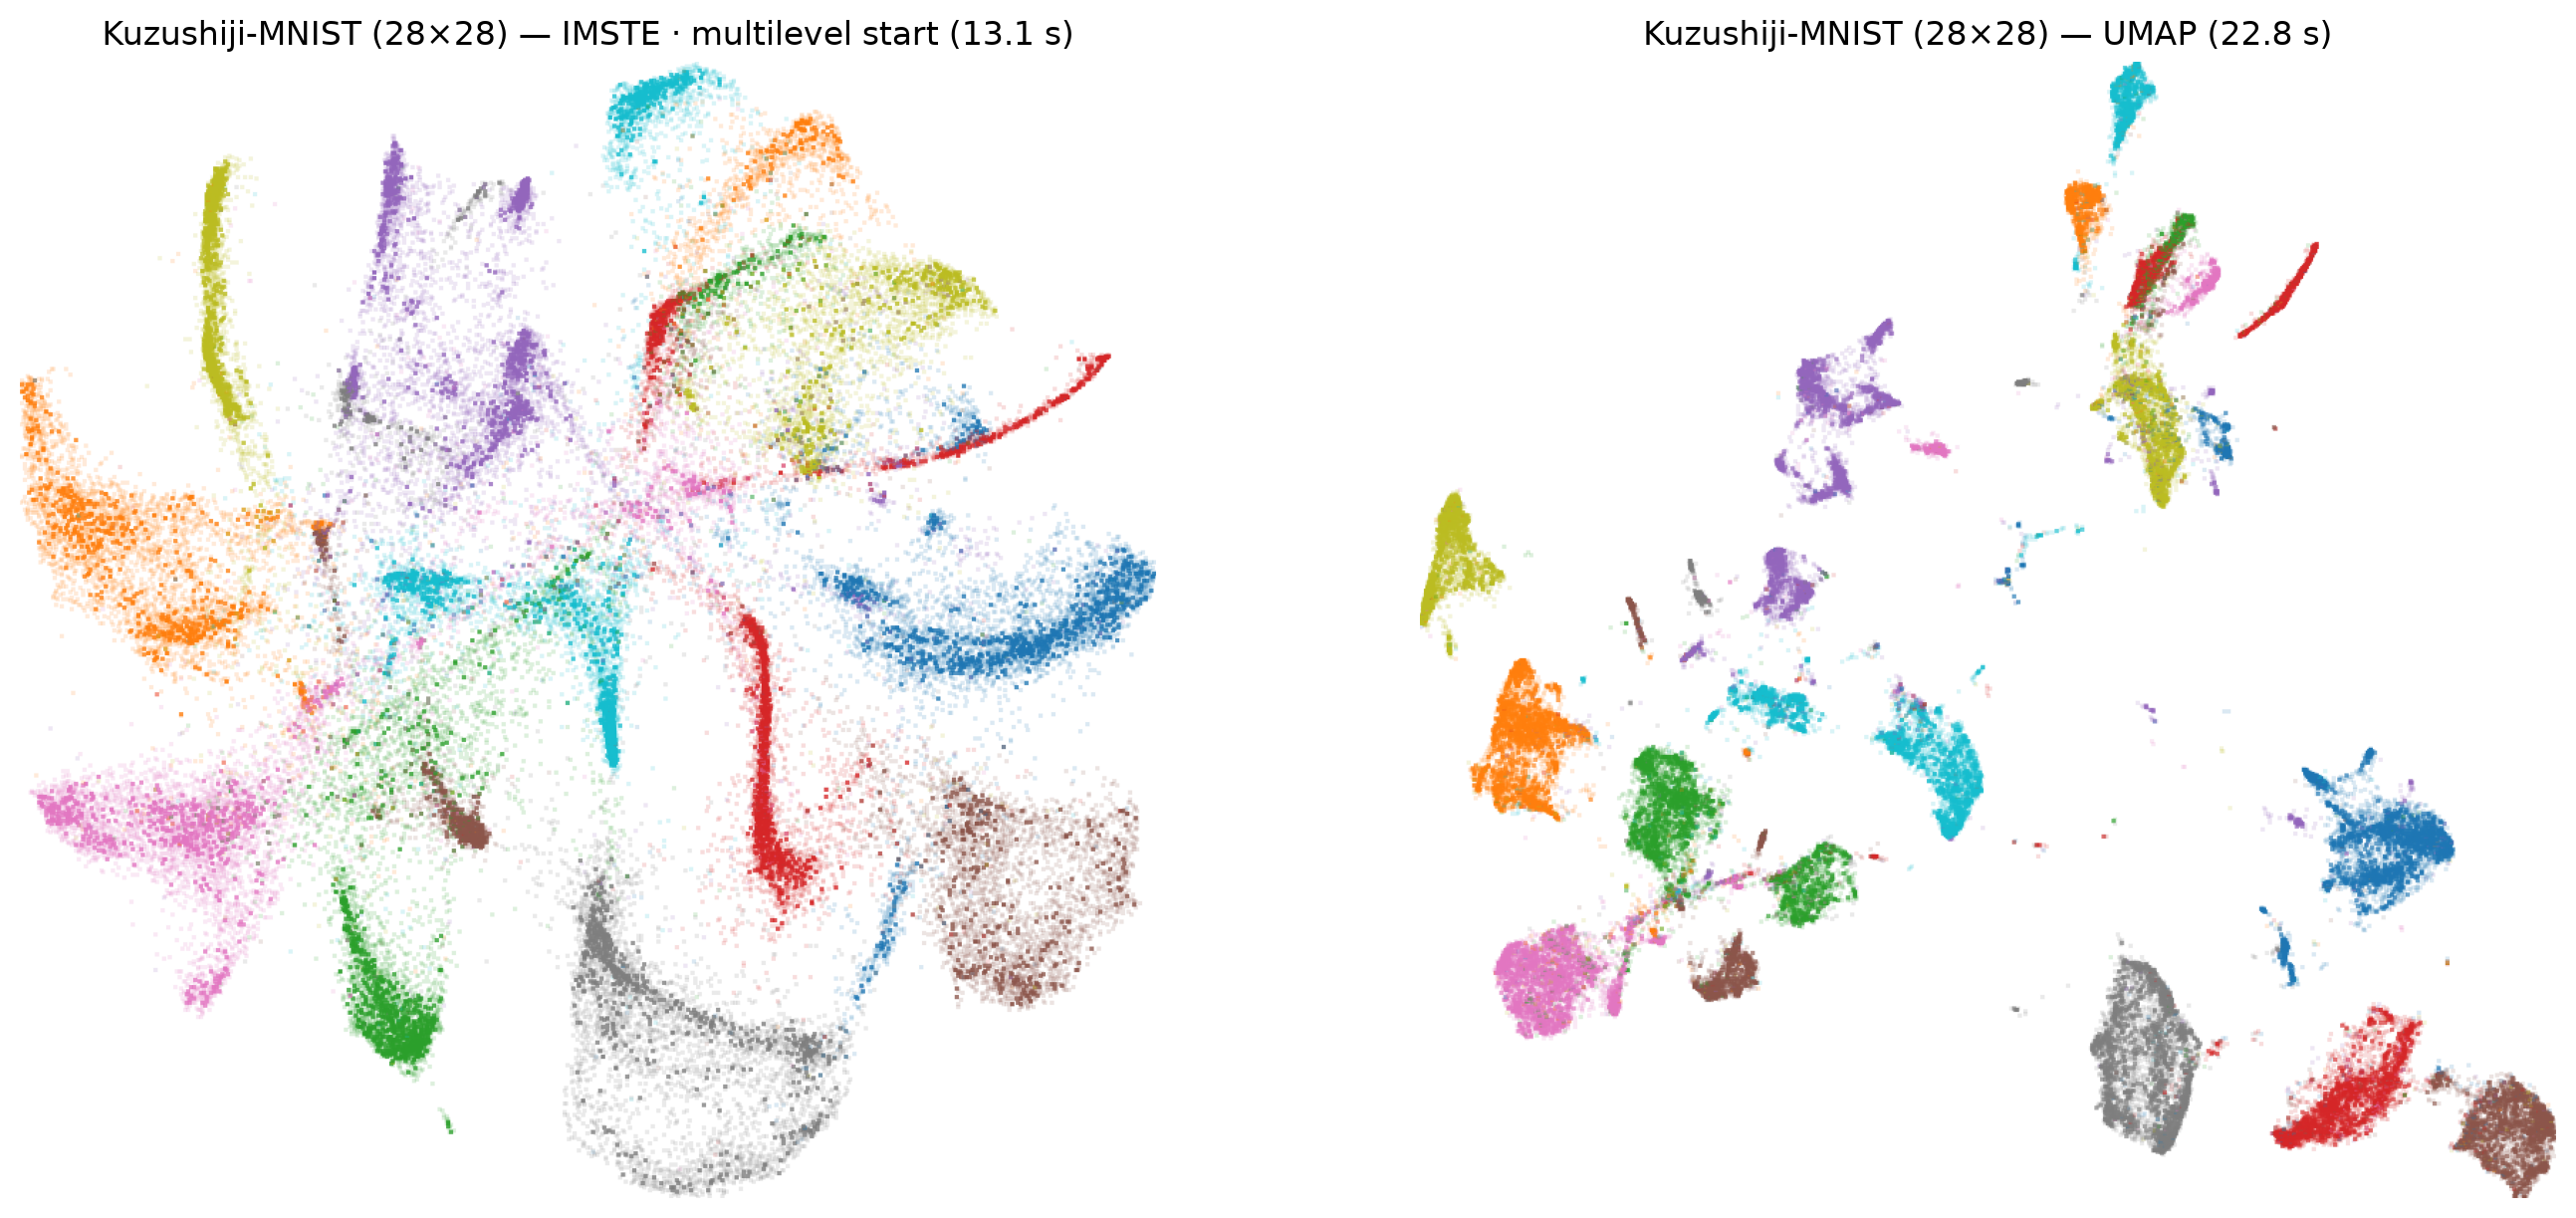

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display
from imste.visualization import render_datashader_embedding

DATASHADER_IMAGES = {}
IMSTE_SECONDS = gallery["summary"].set_index("dataset")["seconds"].to_dict()

for dataset_name, (_, labels) in gallery["datasets"].items():
    embeddings = {
        "IMSTE · multilevel start" if MULTILEVEL_INIT else "IMSTE · PCA start":
            gallery["embeddings"][dataset_name],
    }
    if dataset_name in IMSTE_GRAVITY_RESULTS:
        embeddings["IMSTE · gravity"] = IMSTE_GRAVITY_RESULTS[dataset_name]
    embeddings["UMAP"] = UMAP_RESULTS[dataset_name]
    fig, axes = plt.subplots(1, len(embeddings), figsize=(7 * len(embeddings), 6), constrained_layout=True, squeeze=False)
    for ax, (method, embedding) in zip(axes.ravel(), embeddings.items()):
        image = render_datashader_embedding(
            embedding,
            labels,
            width=RENDER_WIDTH,
            height=RENDER_HEIGHT,
            min_alpha=RENDER_MIN_ALPHA,
            background=RENDER_BACKGROUND,
            spread_px=RENDER_SPREAD_PX,
        )
        DATASHADER_IMAGES[(dataset_name, method)] = image
        ax.imshow(image.to_pil())
        elapsed = (
            (IMSTE_SECONDS[dataset_name] + IMSTE_GRAVITY_SECONDS.get(dataset_name, 0.0))
            if method == "IMSTE · gravity"
            else IMSTE_SECONDS[dataset_name]
            if method.startswith("IMSTE")
            else UMAP_SECONDS[dataset_name]
        )
        runtime = f"{elapsed / 60:.1f} min" if elapsed >= 60 else f"{elapsed:.1f} s"
        ax.set_title(f"{dataset_name} — {method} ({runtime})")
        ax.set_axis_off()
    display(fig)
    plt.close(fig)


## 5. Save embeddings for interactive rendering

This writes one compact cache containing the labels, UMAP coordinates, and IMSTE coordinates for each successfully processed image dataset. Rerun this cell after changing the sample size or fit settings to replace the cached gallery.

In [5]:
from pathlib import Path
import json
import numpy as np

EMBEDDING_CACHE_DIR = repo_root / "data" / "embeddings"
EMBEDDING_CACHE_DIR.mkdir(parents=True, exist_ok=True)
MNIST_EMBEDDINGS_PATH = EMBEDDING_CACHE_DIR / "mnist_gallery_embeddings.npz"
cache = {
    "dataset_names": np.asarray(list(gallery["datasets"]), dtype=str),
    "max_samples": np.asarray(MAX_SAMPLES),
    "random_state": np.asarray(RANDOM_STATE),
    "device": np.asarray(DEVICE),
    "multilevel_init": np.asarray(MULTILEVEL_INIT),
    "pca_init": np.asarray(PCA_INIT),
    "gravity_settings_json": np.asarray(json.dumps(gravity_settings, sort_keys=True) if IMSTE_GRAVITY_ENABLED else "disabled"),
}
for index, (dataset_name, (_, labels)) in enumerate(gallery["datasets"].items()):
    cache[f"labels_{index}"] = np.asarray(labels)
    cache[f"imste_{index}"] = np.asarray(gallery["embeddings"][dataset_name], dtype=np.float32)
    cache[f"umap_{index}"] = np.asarray(UMAP_RESULTS[dataset_name], dtype=np.float32)
    if dataset_name in IMSTE_GRAVITY_RESULTS:
        cache[f"gravity_{index}"] = np.asarray(IMSTE_GRAVITY_RESULTS[dataset_name], dtype=np.float32)
        cache[f"gravity_seconds_{index}"] = np.asarray(float(IMSTE_GRAVITY_SECONDS[dataset_name]))
    cache[f"imste_seconds_{index}"] = np.asarray(
        float(gallery["summary"].set_index("dataset").loc[dataset_name, "seconds"])
    )
    cache[f"umap_seconds_{index}"] = np.asarray(float(UMAP_SECONDS[dataset_name]))
np.savez_compressed(MNIST_EMBEDDINGS_PATH, **cache)
print(f"Saved {len(gallery['datasets'])} datasets to {MNIST_EMBEDDINGS_PATH}")


Saved 3 datasets to /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/embeddings/mnist_gallery_embeddings.npz
